# Cell 1 — Exploratory analysis and visibility annotation

**Purpose:** describe the audited development data and establish a reproducible, human-reviewed
coarse visibility annotation workflow for civilian thermal UAV search and rescue. Research
questions concern original target size, person density, available acquisition metadata, and
observable occlusion. These are exploratory descriptions, not detector performance results.

**Inputs:** a successful Notebook 02 output bundle with published, hashed image/object manifests;
the corresponding mounted images; project source and configuration. For visibility labels,
two actual independent reviewer CSVs and any necessary third-reviewer adjudication are required.
Python 3.11+, PyYAML, Pillow, NumPy, and Matplotlib are used; no GPU, RGB, or internet is required.

**Outputs:** a unique run with verified lineage/configuration, scoped tables, PNG/SVG figures,
an immutable stratified annotation campaign with blank reviewer templates and native-resolution
context/crop images, agreement diagnostics, and a separate versioned visibility sidecar.
Unavailable/unjudgeable/unresolved cases remain masked. No source manifests are overwritten.

Only explicitly allowed development source splits are explored. Test/calibration/unknown splits
are excluded before image access. No training, new evaluation splits, downloads, installations,
or automatic Drive mounts occur. Missing data produce a blocked-input report, not fabricated EDA.
Runtime category: **descriptive analysis / annotation preparation**, with bounded image samples.
Human annotation is an external step and may take substantially longer. Run from a fresh kernel.

In [86]:
import os
from pathlib import Path

working = Path("/kaggle/working")
experiments = working / "artifacts/experiments"

print("Working directory contents:", sorted(p.name for p in working.iterdir()))
print("\nNotebook 02 audit runs:")
for report in sorted(experiments.glob("*/logs/audit_report.json")):
    print(report.parent.parent)

audit_run = experiments / (
    "thermal-sar-dataset-audit_20261120T024854579539Z_30fc5c422d_af17e401"
)

required_files = ("run.json", "logs/audit_report.json")
missing = [name for name in required_files if not (audit_run / name).is_file()]
if not (audit_run / "manifests").is_dir():
    missing.append("manifests/")

if missing:
    raise FileNotFoundError(f"In {audit_run}, missing: {missing}")

os.environ["THERMAL_AUDIT_RUN"] = str(audit_run)
os.environ["THERMAL_PROJECT_ROOT"] = (
    "/kaggle/input/datasets/dule11/thermal-project-root"
)
os.environ["THERMAL_DATASET_ROOT"] = (
    "/kaggle/input/datasets/pandrii000/"
    "hituav-a-highaltitude-infrared-thermal-dataset/hit-uav"
)

print("\nUsing Notebook 02 audit:", audit_run)

Working directory contents: ['.virtual_documents', 'artifacts', 'hit_uav.yaml', 'notebook02_hituav_audit.zip']

Notebook 02 audit runs:
/kaggle/working/artifacts/experiments/thermal-sar-dataset-audit_20261120T023723106124Z_6e488b502e_6869a8c6
/kaggle/working/artifacts/experiments/thermal-sar-dataset-audit_20261120T024854579539Z_30fc5c422d_af17e401

Using Notebook 02 audit: /kaggle/working/artifacts/experiments/thermal-sar-dataset-audit_20261120T024854579539Z_30fc5c422d_af17e401


In [100]:
# Cell 2 — Load and verify the Notebook 02 audit and HIT-UAV mount.
import json
import logging
import os
import sys
from pathlib import Path

from IPython.display import Image as DisplayImage
from IPython.display import display

PROJECT_ROOT = Path("/kaggle/input/datasets/dule11/thermal-project-root")
DATASET_ROOT = Path(
    "/kaggle/input/datasets/pandrii000/"
    "hituav-a-highaltitude-infrared-thermal-dataset/hit-uav"
)
AUDIT_RUN = (
    Path("/kaggle/working/artifacts/experiments")
    / "thermal-sar-dataset-audit_20261120T024854579539Z_30fc5c422d_af17e401"
)

required_files = (
    PROJECT_ROOT / "configs/base.yaml",
    PROJECT_ROOT / "src/data/exploration.py",
    DATASET_ROOT / "dataset.yaml",
    AUDIT_RUN / "run.json",
    AUDIT_RUN / "logs/audit_report.json",
)
missing = [str(path) for path in required_files if not path.is_file()]
if not (AUDIT_RUN / "manifests").is_dir():
    missing.append(str(AUDIT_RUN / "manifests"))
if missing:
    raise FileNotFoundError("Missing Notebook 03 inputs:\n" + "\n".join(missing))

# Optional settings and reviewer inputs used by later cells.
SETTINGS_PATH_HINT = os.environ.get("THERMAL_EXPLORATION_SETTINGS")
OUTPUT_ROOT_HINT = os.environ.get("THERMAL_OUTPUT_ROOT")
CAMPAIGN_PATH_HINT = os.environ.get("THERMAL_VISIBILITY_CAMPAIGN")
REVIEWER_A_HINT = os.environ.get("THERMAL_REVIEWER_A")
REVIEWER_B_HINT = os.environ.get("THERMAL_REVIEWER_B")
ADJUDICATION_HINT = os.environ.get("THERMAL_ADJUDICATIONS")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.exploration import (
    export_exploration,
    initialize_exploration,
    quality_descriptors,
    summarize_exploration,
)
from src.data.visibility import (
    create_campaign,
    export_visibility,
    finalize_visibility,
    select_tasks,
    validate_visibility,
)
from src.visualization.exploration import plot_exploration, plot_visibility

logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s %(name)s: %(message)s",
)

context = initialize_exploration(
    PROJECT_ROOT,
    audit_run=AUDIT_RUN,
    dataset_root=DATASET_ROOT,
    output_root=Path(OUTPUT_ROOT_HINT).expanduser() if OUTPUT_ROOT_HINT else None,
    settings_path=Path(SETTINGS_PATH_HINT).expanduser() if SETTINGS_PATH_HINT else None,
)

run_dir = Path(context["run_dir"])
campaign = None
review_result = None
review_error = None

print(json.dumps(
    {key: context[key] for key in (
        "data_ready", "blockers", "scope", "prior_audit", "run_dir"
    )},
    indent=2,
))

{
  "data_ready": true,
  "blockers": [],
  "scope": {
    "allowed_splits": [
      "train",
      "val",
      "validation",
      "development_validation"
    ],
    "excluded_images": 571,
    "coordinate_space": "original_image_pixels",
    "test_calibration_explored": false
  },
  "prior_audit": {
    "run_directory": "/kaggle/working/artifacts/experiments/thermal-sar-dataset-audit_20261120T024854579539Z_30fc5c422d_af17e401",
    "experiment_id": "thermal-sar-dataset-audit_20261120T024854579539Z_30fc5c422d_af17e401",
    "configuration_sha256": "010a2d145888e1914789e4572fa6a480f23b0a834497968c8b7e125b580fc05b",
    "audit_status": "audited_structural_only"
  },
  "run_dir": "/kaggle/working/artifacts/experiments/thermal-sar-exploration_20261120T030644840893Z_31979a8a20_f3caf1cb"
}


In [101]:
# Cell 3 — Summarize actual scoped images, persons, empty scenes, datasets, and metadata availability.
# Prepare bounded image descriptors once, so subsequent grouped figures use the same recorded sample.
if context["data_ready"]:
    context["analysis"] = summarize_exploration(context["images"], context["objects"], context["settings"])
    context["quality"] = quality_descriptors(context["images"], context["settings"])
    print(json.dumps(context["analysis"]["summary"], indent=2))
else:
    print("BLOCKED: no real scoped observations available. No observation tables or figures are generated.")

{
  "images": 2295,
  "persons": 9701,
  "crowd_objects": 0,
  "empty_images": 0,
  "person_negative_images": 959,
  "datasets": {
    "HIT-UAV": 2295
  },
  "size_groups_noncrowd": {
    "small": 9678,
    "medium": 23
  },
  "altitude_available_images": 0,
  "view_angle_available_images": 0
}


Image geometry samples: [{'dataset_id': 'HIT-UAV', 'image_id': 'images/train/0_100_30_0_03280.jpg', 'split': 'train', 'width': 640, 'height': 512, 'aspect_ratio': 1.25, 'persons': 0, 'altitude_m': None, 'view_angle_deg': None, 'flight_id': None, 'sequence_id': None}, {'dataset_id': 'HIT-UAV', 'image_id': 'images/train/0_100_30_0_03281.jpg', 'split': 'train', 'width': 640, 'height': 512, 'aspect_ratio': 1.25, 'persons': 8, 'altitude_m': None, 'view_angle_deg': None, 'flight_id': None, 'sequence_id': None}, {'dataset_id': 'HIT-UAV', 'image_id': 'images/train/0_100_30_0_03284.jpg', 'split': 'train', 'width': 640, 'height': 512, 'aspect_ratio': 1.25, 'persons': 3, 'altitude_m': None, 'view_angle_deg': None, 'flight_id': None, 'sequence_id': None}]


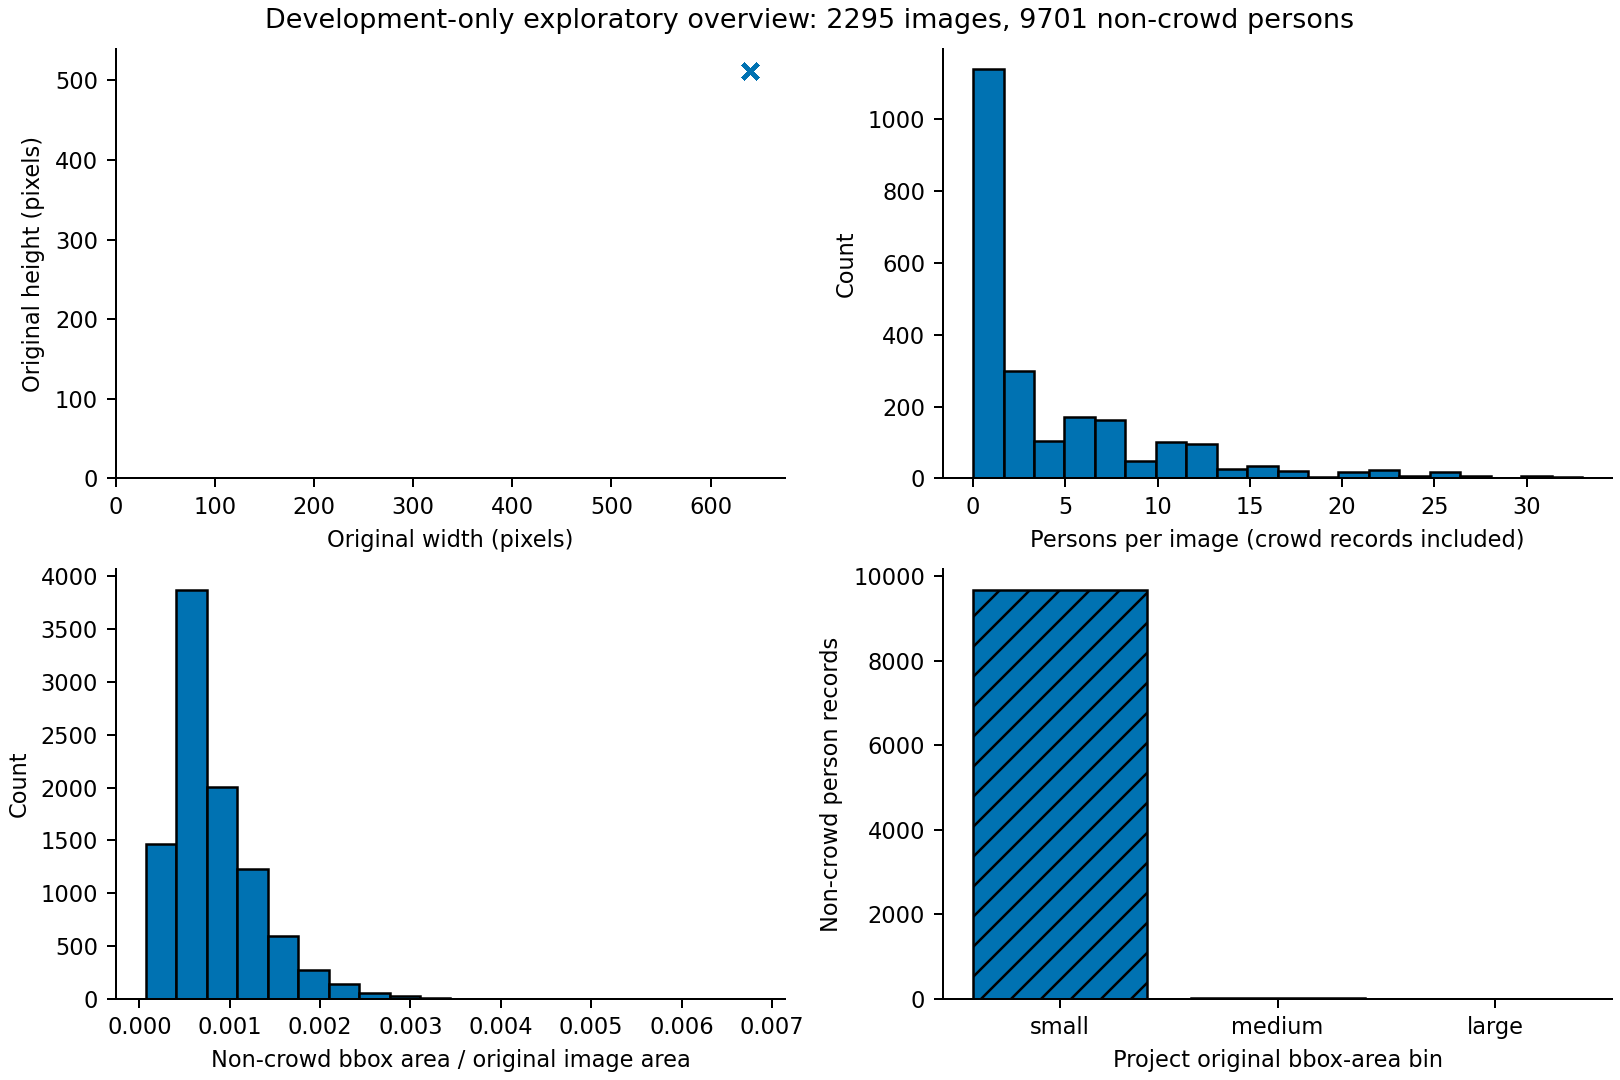

In [102]:
# Cell 4 — Render shared exploratory figures; inspect original image dimensions and aspect ratios.
if context["data_ready"]:
    plot_exploration(context)
    print("Image geometry samples:", context["analysis"]["image_rows"][:3])
    display(DisplayImage(filename=str(run_dir / "figures/exploratory_overview.png")))

In [104]:
# Cell 5 — Person density and verified negatives, including zero-person development images.
if context["data_ready"]:
    print("Persons per image:", [(row["image_id"], row["persons"]) for row in context["analysis"]["image_rows"][:12]])
    print("Summary:", context["analysis"]["summary"])
    print("Crowd source records are counted explicitly; they are excluded from individual visibility tasks.")

Persons per image: [('images/train/0_100_30_0_03280.jpg', 0), ('images/train/0_100_30_0_03281.jpg', 8), ('images/train/0_100_30_0_03284.jpg', 3), ('images/train/0_100_30_0_03288.jpg', 4), ('images/train/0_100_30_0_03289.jpg', 2), ('images/train/0_100_30_0_03291.jpg', 3), ('images/train/0_100_30_0_03292.jpg', 4), ('images/train/0_100_30_0_03294.jpg', 2), ('images/train/0_100_30_0_03298.jpg', 7), ('images/train/0_100_30_0_03301.jpg', 6), ('images/train/0_100_30_0_03302.jpg', 1), ('images/train/0_100_30_0_03304.jpg', 7)]
Summary: {'images': 2295, 'persons': 9701, 'crowd_objects': 0, 'empty_images': 0, 'person_negative_images': 959, 'datasets': {'HIT-UAV': 2295}, 'size_groups_noncrowd': {'small': 9678, 'medium': 23}, 'altitude_available_images': 0, 'view_angle_available_images': 0}
Crowd source records are counted explicitly; they are excluded from individual visibility tasks.


In [105]:
# Cell 6 — Original-coordinate width, height, relative area, and apparent person-size distributions.
if context["data_ready"]:
    print("Per-person geometry samples:", context["analysis"]["object_rows"][:5])
    print("Typed JSON and CSV observation tables are exported in Cell 20; histogram bins are recorded with figures.")

Per-person geometry samples: [{'dataset_id': 'HIT-UAV', 'image_id': 'images/train/0_100_30_0_03281.jpg', 'object_id': None, 'annotation_row': 4, 'width_px': 7.000000000000028, 'height_px': 14.0, 'area_px2': 98.0000000000004, 'relative_area': 0.0002990722656250012, 'relative_height': 0.02734375, 'size_group': 'small', 'iscrowd': False, 'altitude_m': None, 'split': 'train'}, {'dataset_id': 'HIT-UAV', 'image_id': 'images/train/0_100_30_0_03281.jpg', 'object_id': None, 'annotation_row': 5, 'width_px': 7.0, 'height_px': 15.0, 'area_px2': 105.0, 'relative_area': 0.0003204345703125, 'relative_height': 0.029296875, 'size_group': 'small', 'iscrowd': False, 'altitude_m': None, 'split': 'train'}, {'dataset_id': 'HIT-UAV', 'image_id': 'images/train/0_100_30_0_03281.jpg', 'object_id': None, 'annotation_row': 6, 'width_px': 6.0, 'height_px': 16.0, 'area_px2': 96.0, 'relative_area': 0.00029296875, 'relative_height': 0.03125, 'size_group': 'small', 'iscrowd': False, 'altitude_m': None, 'split': 'train

In [106]:
# Cell 7 — Define and inspect disjoint target-size bins, without resized-coordinate or mask-area confusion.
print("Coordinate space:", context["settings"]["size_coordinate_space"])
print("Original bbox-area boundaries (pixels squared):", context["settings"]["size_area_boundaries_px2"])
print("Project definition: small A < 1024, medium 1024 <= A < 9216, large A >= 9216 by default.")
print("These are project bbox bins inspired by common size thresholds, not COCO mask-area AP results.")
if context["data_ready"]:
    print("Non-crowd counts:", context["analysis"]["summary"]["size_groups_noncrowd"])

Coordinate space: original_image
Original bbox-area boundaries (pixels squared): [1024, 9216]
Project definition: small A < 1024, medium 1024 <= A < 9216, large A >= 9216 by default.
These are project bbox bins inspired by common size thresholds, not COCO mask-area AP results.
Non-crowd counts: {'small': 9678, 'medium': 23}


Declared camera angle key: None
Metadata counts: {'altitude_available_images': 0, 'view_angle_available_images': 0}


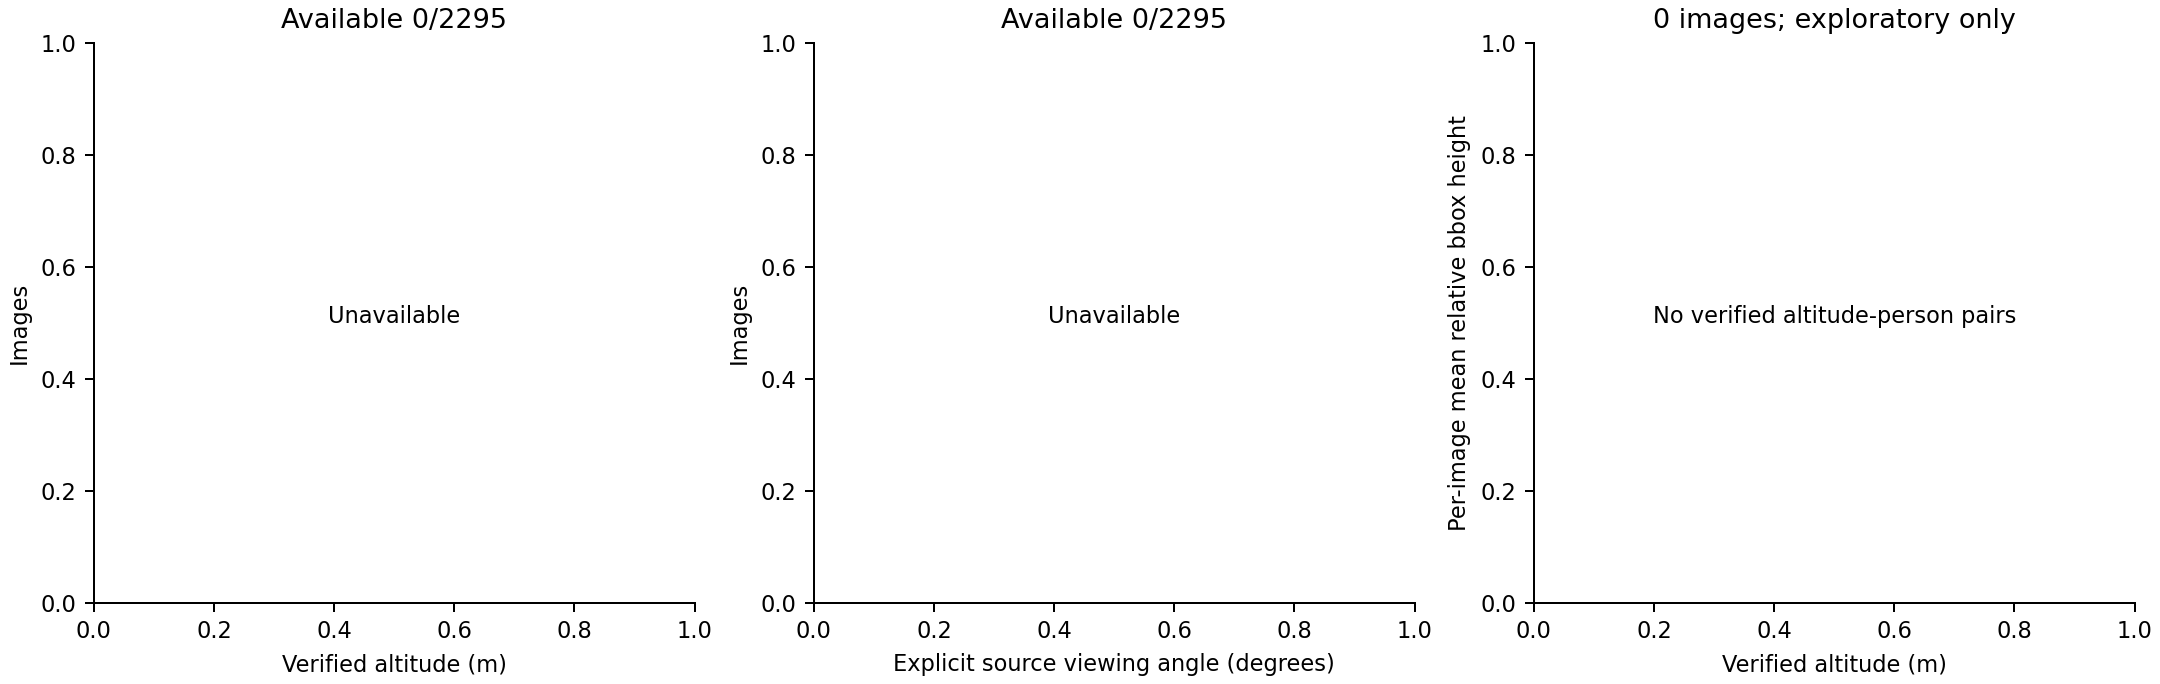

No camera key, flight ID, altitude, or radiometric temperature is inferred from filenames or box sizes.


In [107]:
# Cell 8 — Verified altitude and explicitly configured camera viewing angle; never infer unavailable values.
print("Declared camera angle key:", context["settings"]["camera_view_angle_key"])
if context["data_ready"]:
    print("Metadata counts:", {key: value for key, value in context["analysis"]["summary"].items() if "available" in key})
    display(DisplayImage(filename=str(run_dir / "figures/metadata_and_apparent_size.png")))
print("No camera key, flight ID, altitude, or radiometric temperature is inferred from filenames or box sizes.")

In [108]:
# Cell 9 — Inspect altitude/apparent-size association only where verified paired observations exist.
print("The metadata figure uses one mean relative person height per image, with the image-pair count shown.")
print("Repeated images/flights remain dependent; no independent-frame p-values, causal claim or fitted altitude model is produced.")
print("Altitude is not used as an inference-time input or manufactured from ground-truth target size.")

The metadata figure uses one mean relative person height per image, with the image-pair count shown.
Repeated images/flights remain dependent; no independent-frame p-values, causal claim or fitted altitude model is produced.
Altitude is not used as an inference-time input or manufactured from ground-truth target size.


Bounded descriptor sample: [{'dataset_id': 'HIT-UAV', 'image_id': 'images/train/1_70_80_0_07754.jpg', 'status': 'descriptive_only', 'p95_minus_p05': 72.0, 'laplacian_variance_display': 0.0007007202120366352, 'highpass_mad_display': 0.0019607843137254832, 'display_conversion': 'native 8-bit channels; RGB display conversion only'}, {'dataset_id': 'HIT-UAV', 'image_id': 'images/train/1_110_60_0_09121.jpg', 'status': 'descriptive_only', 'p95_minus_p05': 165.0, 'laplacian_variance_display': 0.000901561994600326, 'highpass_mad_display': 0.0019607843137254832, 'display_conversion': 'native 8-bit channels; RGB display conversion only'}, {'dataset_id': 'HIT-UAV', 'image_id': 'images/train/1_120_80_0_06149.jpg', 'status': 'descriptive_only', 'p95_minus_p05': 72.0, 'laplacian_variance_display': 0.0004984195754003964, 'highpass_mad_display': 0.0019607843137254832, 'display_conversion': 'native 8-bit channels; RGB display conversion only'}]


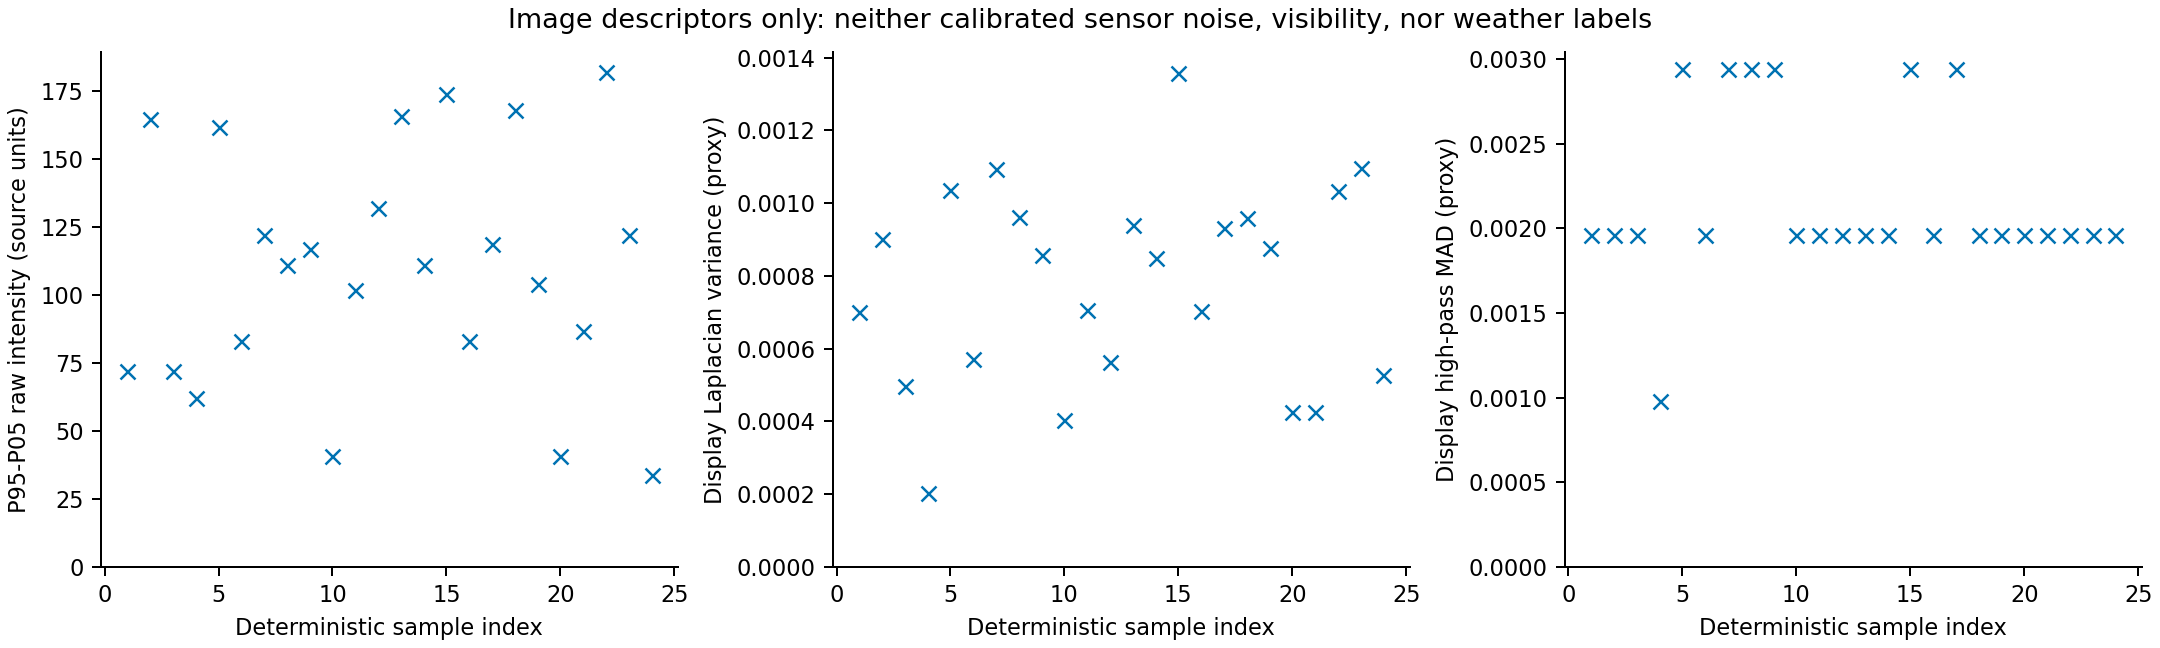

P95-P05 is raw source intensity spread. Laplacian variance/high-pass MAD are scene-confounded display proxies.
No real blur/noise/weather labels or calibrated sensor/temperature measurements are inferred.
Target context/crop images for reviewer inspection are exported in Cell 14.


In [109]:
# Cell 10 — Thermal image contrast and structure descriptors, with explicit confounding and display conversion.
if context["data_ready"]:
    print("Bounded descriptor sample:", context["quality"][:3])
    display(DisplayImage(filename=str(run_dir / "figures/image_descriptor_proxies.png")))
print("P95-P05 is raw source intensity spread. Laplacian variance/high-pass MAD are scene-confounded display proxies.")
print("No real blur/noise/weather labels or calibrated sensor/temperature measurements are inferred.")
print("Target context/crop images for reviewer inspection are exported in Cell 14.")

## Cell 11 — Observable categorical visibility protocol

Protocol version **1.0**, three supervised categories plus a masked outcome:

- **fully_visible:** no apparent obstruction of the identifiable person extent. This is not
  proof that every body part or pixel is visible.
- **partially_occluded:** an external obstruction hides some identifiable body structure,
  while a substantial structure remains discernible.
- **heavily_occluded:** an external obstruction leaves only limited identifiable structure.
- **unjudgeable:** resolution, truncation, contrast, pose or ambiguity prevents a defensible
  occlusion category. Visibility stays null and its training-availability mask stays false.

These are operational coarse judgments; no precise visible-area fraction is claimed. Examine
both source context and target crop. If occlusion cannot be distinguished from pose/truncation
or thermal ambiguity, choose unjudgeable. Crowd boxes are ineligible for individual labels.
Pilot these rules and inspect disagreement before scaling an annotation campaign.

Two distinct pseudonymous reviewers must label independently. Do not expose another reviewer's
CSV until independent labels are complete. Software checks distinct IDs and records provenance;
it cannot prove two identities represent independent humans. Disagreements require a third
adjudicator and a reason. Unfinished labels remain unavailable. The detection confidence score
will never be mechanically multiplied by a visibility category.

## Cell 12 — Real visibility versus synthetic augmentation

Annotate only observed obstruction in original dataset images. This notebook applies no
synthetic occlusion, blur, noise, copy-paste or weather overlay. Native-resolution crops do
not create spatial detail. Eight-bit source display is preserved; supported higher-bit-depth
scalar images use a disclosed whole-image linear min/max display conversion, with the same
conversion for context and crop. Raw images remain untouched and are not treated as temperatures.

Later augmentation must update valid visibility targets when defensible or mask affected
supervision. Synthetic software-test labels are explicitly fixtures, never real annotations
or evidence of weather robustness. No test-set labels guide protocol choices here.

In [110]:
# Cell 13 — Deterministic stratified non-crowd person subset; source splits are preserved.
tasks = select_tasks(context["images"], context["objects"], context["settings"]) if context["data_ready"] else []
print("Selected tasks:", len(tasks), "cap:", context["settings"]["annotation_sample_size"])
print("Strata: source dataset/split, original bbox-size bin, and verified-altitude availability.")
print("Balanced round-robin sampling is reproducible but not population-proportional; do not infer prevalence from it.")
print("Internal object_key references are not source person identities or track IDs.")

Selected tasks: 60 cap: 60
Strata: source dataset/split, original bbox-size bin, and verified-altitude availability.
Balanced round-robin sampling is reproducible but not population-proportional; do not infer prevalence from it.
Internal object_key references are not source person identities or track IDs.


In [111]:
# Cell 14 — Export blank reviewer templates/context/crop images, or verify the exact original campaign.
if context["data_ready"]:
    campaign = create_campaign(context, Path(CAMPAIGN_PATH_HINT).expanduser() if CAMPAIGN_PATH_HINT else None)
    assert campaign["tasks"] == tasks
    print("Campaign:", context["campaign_dir"])
    print("Campaign ID:", campaign["campaign_id"], "protocol SHA-256:", campaign["protocol_sha256"])
    print("Distribute reviewer_a.csv and reviewer_b.csv separately with the protocol and task images.")
else:
    print("No campaign tasks generated because the audited real inputs are missing.")

Campaign: /kaggle/working/artifacts/experiments/thermal-sar-exploration_20261120T030644840893Z_31979a8a20_f3caf1cb/annotations/campaign
Campaign ID: c0ae42812747cf75ab8566df38e73832db50ae9bf0d663b39976974a2a648681 protocol SHA-256: 0126c9cc37bbd8e963273b4c1b6fdb65a976b79a2355943c1e15396812960b45
Distribute reviewer_a.csv and reviewer_b.csv separately with the protocol and task images.


In [112]:
# Cell 15 — Import actual independent reviewer CSVs; absent/blank reviews never become labels.
reviewer_paths = [Path(value).expanduser() for value in (REVIEWER_A_HINT, REVIEWER_B_HINT) if value]
if campaign is not None:
    try:
        review_result = finalize_visibility(context, campaign, reviewer_paths)
        print("Review import summary:", review_result["summary"])
    except (ValueError, FileNotFoundError) as exc:
        review_error = f"{type(exc).__name__}: {exc}"
        context["blockers"].append(review_error)
        context["status"] = "blocked_review_inputs"
        print("BLOCKED reviewer import:", review_error)

Review import summary: {'person_objects': 9701, 'selected_objects': 60, 'reviewer_files': 0, 'paired_objects': 0, 'supervised_labels': 0, 'statuses': {'not_selected': 9641, 'awaiting_review': 60}, 'input_hashes': {}, 'disagreements_requiring_review': []}


In [113]:
# Cell 16 — Two-rater categorical agreement on actual paired selected objects only.
if review_result is not None:
    print(json.dumps(review_result["agreement"], indent=2))
print("Unweighted Cohen kappa: (p_observed - p_expected) / (1 - p_expected); unjudgeable is included as a category.")
print("No pairs or degenerate marginals -> null kappa. No significance, CI or independent-frame assumption is supplied.")
# Formula reference: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.cohen_kappa_score.html

{
  "paired_objects": 0,
  "observed_agreement": null,
  "expected_agreement": null,
  "cohen_kappa": null,
  "categories": [
    "fully_visible",
    "partially_occluded",
    "heavily_occluded",
    "unjudgeable"
  ],
  "confusion_matrix": [
    [
      0,
      0,
      0,
      0
    ],
    [
      0,
      0,
      0,
      0
    ],
    [
      0,
      0,
      0,
      0
    ],
    [
      0,
      0,
      0,
      0
    ]
  ],
  "definition": "kappa=(p_observed-p_expected)/(1-p_expected); unjudgeable included as a category",
  "limitation": "Descriptive on paired selected objects only; no CI/p-value, prevalence claim or independence guarantee",
  "undefined_reason": "No pairs or degenerate single-category marginals"
}
Unweighted Cohen kappa: (p_observed - p_expected) / (1 - p_expected); unjudgeable is included as a category.
No pairs or degenerate marginals -> null kappa. No significance, CI or independent-frame assumption is supplied.


In [114]:
# Cell 17 — Explicit third-reviewer adjudication; unresolved disagreement remains masked.
if review_result is not None and campaign is not None:
    try:
        resolved = finalize_visibility(context, campaign, reviewer_paths,
                                      Path(ADJUDICATION_HINT).expanduser() if ADJUDICATION_HINT else None)
        for path, digest in review_result["summary"]["input_hashes"].items():
            if resolved["summary"]["input_hashes"].get(path) != digest:
                raise ValueError("Reviewer CSV changed between agreement and adjudication; restart with fixed inputs")
        context["visibility"] = resolved
        statuses = resolved["summary"]["statuses"]
        context["status"] = ("awaiting_independent_annotations" if statuses.get("awaiting_review", 0)
                             else "awaiting_adjudication" if statuses.get("awaiting_adjudication", 0)
                             else "annotation_campaign_complete" if campaign["tasks"] else "no_eligible_person_tasks")
        print("Decision summary:", resolved["summary"])
    except (ValueError, FileNotFoundError) as exc:
        context["blockers"].append(f"{type(exc).__name__}: {exc}")
        context["status"] = "blocked_review_inputs"
        print("BLOCKED adjudication:", exc)

Decision summary: {'person_objects': 9701, 'selected_objects': 60, 'reviewer_files': 0, 'paired_objects': 0, 'supervised_labels': 0, 'statuses': {'not_selected': 9641, 'awaiting_review': 60}, 'input_hashes': {}, 'disagreements_requiring_review': []}


{
  "HIT-UAV / medium": {
    "masked_or_unavailable": 23
  },
  "HIT-UAV / small": {
    "masked_or_unavailable": 9678
  }
}


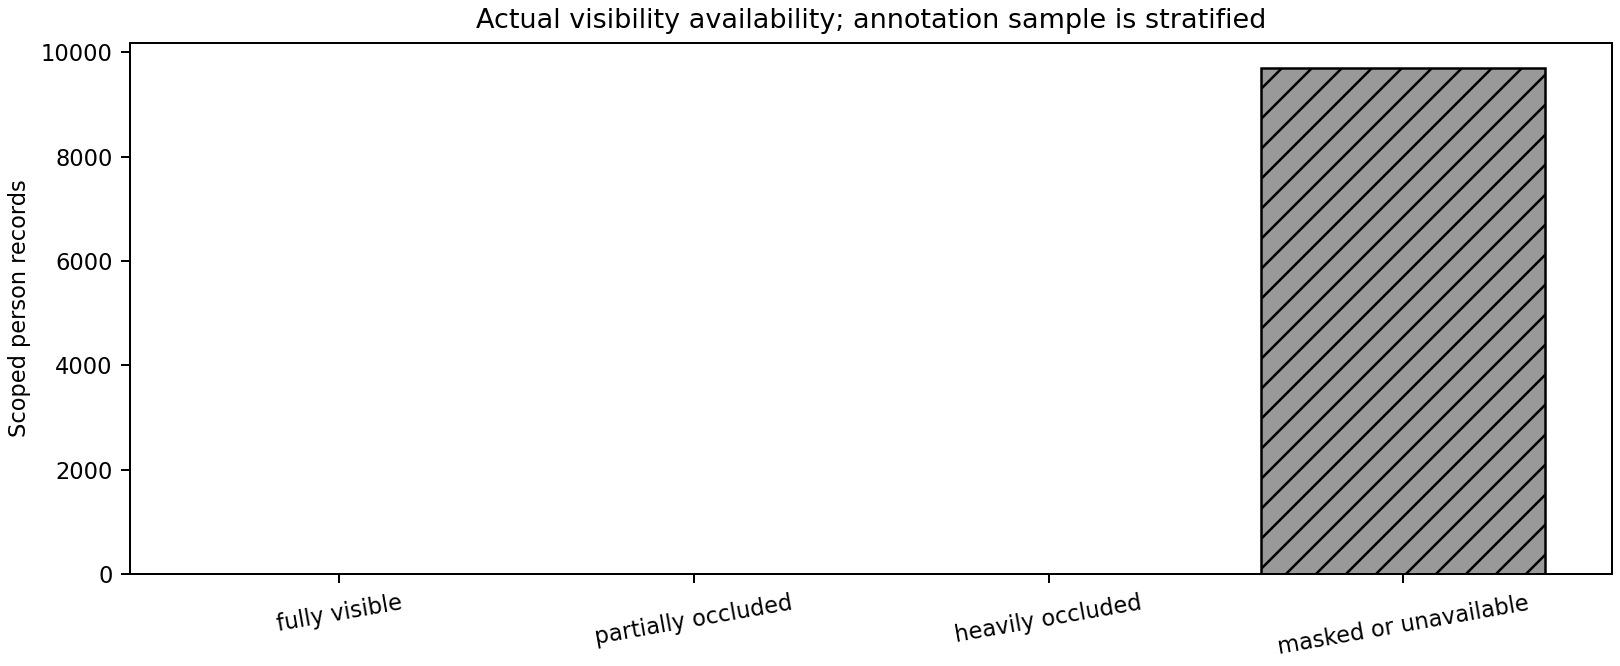

Masked rows include not selected, unfinished, unresolved, crowd and unjudgeable cases; none become fully-visible labels.


In [115]:
# Cell 18 — Audit visibility categories/availability by source dataset and original target-size group.
if context["visibility"] is not None:
    plot_visibility(context)
    print(json.dumps(context["visibility_distribution"], indent=2))
    display(DisplayImage(filename=str(run_dir / "figures/visibility_availability.png")))
print("Masked rows include not selected, unfinished, unresolved, crowd and unjudgeable cases; none become fully-visible labels.")

In [116]:
# Cell 19 — Export a separate versioned visibility sidecar and availability masks, preserving Notebook 02.
if context["visibility"] is not None:
    validate_visibility(context["visibility"]["labels"], context["objects"], campaign)
    export_visibility(context)
    print("Visibility sidecar:", run_dir / "manifests/visibility.jsonl")
    print("Actual supervised labels:", context["visibility"]["summary"]["supervised_labels"])
else:
    print("No visibility sidecar emitted: audited observations or valid reviewer inputs are unavailable.")

Visibility sidecar: /kaggle/working/artifacts/experiments/thermal-sar-exploration_20261120T030644840893Z_31979a8a20_f3caf1cb/manifests/visibility.jsonl
Actual supervised labels: 0


In [117]:
# Cell 20 — Export descriptive tables/figures, protocol, lineage, and the honest readiness report.
export_exploration(context)
saved = json.loads((run_dir / "logs/exploration_report.json").read_text(encoding="utf-8"))
print("Artifacts:", run_dir)
print("Status:", saved["status"], "data ready:", saved["data_ready"], "training ready:", saved["training_ready"])
print("Remaining blockers:", saved["blockers"])
print("Split fingerprint remains:", context["config"]["split"]["fingerprint"])

INFO src.data.exploration: Notebook 03 exported: /kaggle/working/artifacts/experiments/thermal-sar-exploration_20261120T030644840893Z_31979a8a20_f3caf1cb


Artifacts: /kaggle/working/artifacts/experiments/thermal-sar-exploration_20261120T030644840893Z_31979a8a20_f3caf1cb
Status: awaiting_independent_annotations data ready: True training ready: False
Remaining blockers: []
Split fingerprint remains: None


## Cell 21 — Interpretation, limitations, run steps, and stop condition

Read `logs/exploration_report.json` before claiming real EDA or annotation completion.
Default local execution remains blocked until a real Notebook 02 audit publishes manifests.
Missing acquisition metadata, visibility or identity labels stay missing. Descriptive figures
and scene-confounded proxies do not prove detector gains, real-weather robustness, calibration
or physical image quality. Stratified annotation counts do not estimate dataset prevalence.
No final-test labels, research splits, or split fingerprints are created here.

**Kaggle/Colab first pass:** make project source, the successful Notebook 02 output bundle,
and the corresponding images available. In Cell 2 set actual `PROJECT_ROOT_HINT`,
`AUDIT_RUN_HINT`, and `DATASET_ROOT_HINT`. Optionally select a writable copy of
`configs/exploration.yaml` with `SETTINGS_PATH_HINT`. Restart and Run All. Kaggle outputs
default under `/kaggle/working/artifacts/experiments/`; Colab under `/content/artifacts/experiments/`.
Keep source data and prior audit bundles read-only. No Drive mount or installation is run.

**Human review:** preserve `annotations/campaign/` from the first pass. Two reviewers complete
separate copies of its blank CSVs using only their own observations and the same protocol.
Provide those CSV paths as `REVIEWER_A_HINT` and `REVIEWER_B_HINT`, and the original campaign
directory as `CAMPAIGN_PATH_HINT`. Restart and Run All to compute agreement and list unresolved
object keys. A third reviewer fills the adjudication template only for completed disagreements,
including a reason; supply `ADJUDICATION_HINT` and rerun. Do not modify the campaign, protocol,
source manifests or split scope between passes. Each pass creates a fresh result directory.

Full contracts and commands are in `docs/Notebook03.md`. Before scaling annotation, review
protocol clarity, agreement counts, missingness and subgroup coverage. No training is authorized
by completing a campaign. Next is Notebook 04 (leakage control/evaluation splits), only after
instruction and real audited inputs. **Stop here.**

Sources: [Cohen kappa definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.cohen_kappa_score.html),
[COCO evaluator source for the distinction from its native area protocol](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py).